In [35]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
import pywt
import optuna
import logging
from scipy.signal import butter, filtfilt
from sklearn.svm import SVR 
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, r2_score
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import LSTM, Dense, Dropout
import keras_tuner as kt

# Load Data and Exploratory Data Analysis

In [13]:
df = pd.read_excel("/Users/asyzyni/Desktop/Capstone/Data Rapih Capstone/Data Capstone Fix BGt.xlsx", parse_dates=['Tanggal'], index_col='Tanggal')

In [14]:
df.head()

,Kelembapan Rata-Rata Udara Harian (%),Temperatur Rata-Rata Harian,Temperatur Maksimum Harian,Temperature Minimum Harian,Angin Rata-Rata Harian (Knot),Curah Hujan,Penyinaran Harian (%),Penguapan Harian (mm),Tekanan Udara Harian (mb)
Tanggal,,,,,,,,,
2018-01-01,87.0,27.2,30.2,22.7,2.5,0,0.0,5.4,1008.0
2018-01-02,85.0,27.3,32.4,24.2,2.7,0,100.0,3.5,1008.5
2018-01-03,77.0,29.7,32.6,24.6,2.1,0,65.0,4.0,1009.3
2018-01-04,80.0,28.3,31.8,25.2,2.3,0,43.8,5.2,1009.1
2018-01-05,81.0,28.4,32.2,24.3,2.4,6,56.3,2.8,1009.8


In [15]:
df.isnull().sum()

Kelembapan Rata-Rata Udara Harian (%)    0
Temperatur Rata-Rata Harian              0
Temperatur Maksimum Harian               0
Temperature Minimum Harian               0
Angin Rata-Rata Harian (Knot)            0
Curah Hujan                              0
Penyinaran Harian (%)                    0
Penguapan Harian (mm)                    0
Tekanan Udara Harian (mb)                0
dtype: int64

In [16]:
df.duplicated().sum()

0

In [17]:
# penanganan khusus TTU 
df['Curah Hujan'] = df['Curah Hujan'].replace('TTU', 0.1)

/var/folders/v6/s7jbz6sn6qv9dh421jb6jbsm0000gn/T/ipykernel_42807/2679362525.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['Curah Hujan'] = df['Curah Hujan'].replace('TTU', 0.1)


visualisasi time series plot

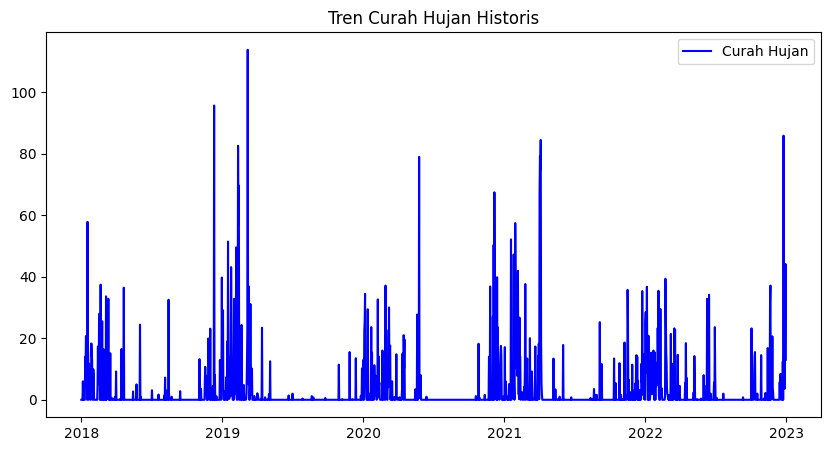

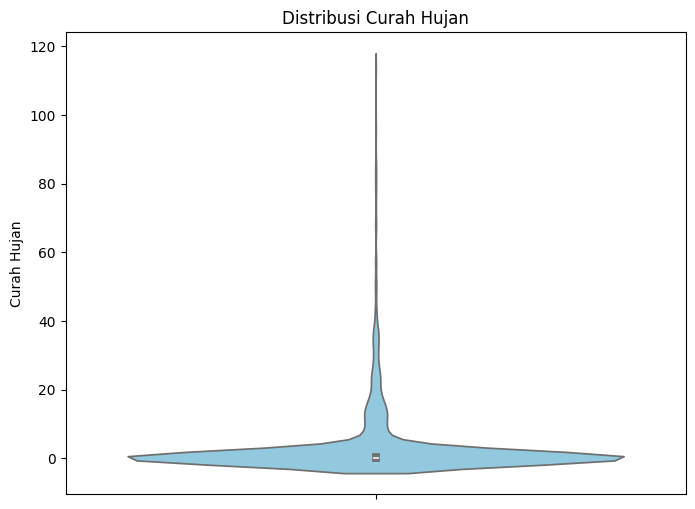

In [19]:
plt.figure(figsize=(10,5))
plt.plot(df['Curah Hujan'], label='Curah Hujan', color='blue')
plt.title('Tren Curah Hujan Historis')
plt.legend()
plt.show()

plt.figure(figsize=(8,6))
sns.violinplot(y=df['Curah Hujan'], color='skyblue')
plt.title('Distribusi Curah Hujan')
plt.show()

violin plot ini menjelaskan kalau sebagian besar curah hujan berada di angka 0. 

analisis autokorelasi

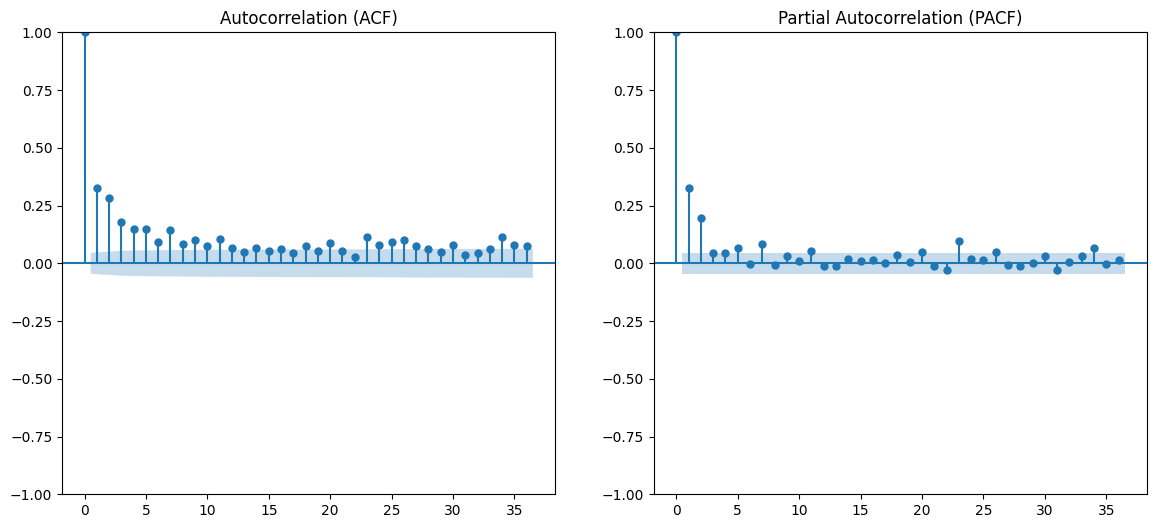

In [23]:
plt.figure(figsize=(14, 6))
plt.subplot(121)
plot_acf(df['Curah Hujan'], lags=36, ax=plt.gca()) # Cek korelasi hingga 3 tahun (36 bulan) ke belakang
plt.title('Autocorrelation (ACF)')

plt.subplot(122)
plot_pacf(df['Curah Hujan'], lags=36, ax=plt.gca())
plt.title('Partial Autocorrelation (PACF)')
plt.show()

plot acf : Curah hujan hari ini masih dipengaruhi oleh beberapa hari sebelumnya, terutama 1–3 hari terakhir. 

PACF : Pengaruh utama datang dari 1–2 periode sebelumnya saja

mungkin timestepnya cukup 3-7

Correlation MAtrix

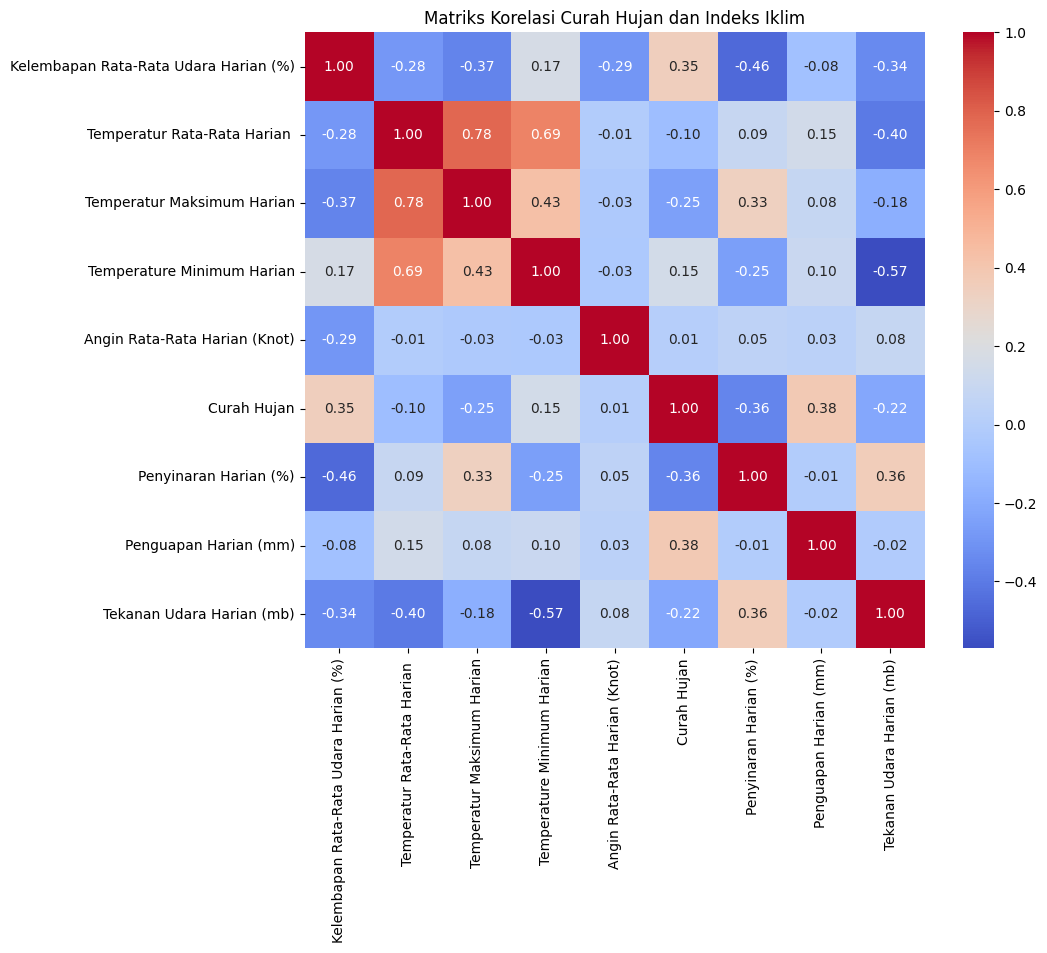

In [24]:
# Cek korelasi linear biasa (Pearson)
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Matriks Korelasi Curah Hujan dan Indeks Iklim')
plt.show()

uji stasioneritas 

karena svm biasanya butuh data yang stasioner

In [26]:
result = adfuller(df['Curah Hujan'].dropna())
print('ADF Statistic:', result[0])
print('p-value:', result[1])

if result[1] <= 0.05:
    print("Data kuat dugaan Stasioner (Siap untuk SVM/LSTM).")
else:
    print("Data Non-Stasioner")

ADF Statistic: -5.989552308029617
p-value: 1.75893394859384e-07
Data kuat dugaan Stasioner (Siap untuk SVM/LSTM).


# Preprocessing + Pseudo-Wavelet

In [44]:
cols_to_use = [
    'Curah Hujan',                            # Target (Index 0)
    'Kelembapan Rata-Rata Udara Harian (%)',  # Fitur Pembantu 1
    'Penyinaran Harian (%)',                  # Fitur Pembantu 2
    'Penguapan Harian (mm)'                   # Fitur Pembantu 3
]

alasan tiga kolom itu dipakai : 

- Kelembapan Rata-Rata Udara (%) -> 0.35

- Penguapan Harian -> 0.38

- Penyinaran  Harian-> -0.36 (tapi ini kalau penyinaran matahari tinggi berarti kemarau begitupun sebaliknya) 

In [43]:
df_selected = df[cols_to_use]

# Normalisasi data ke skala 0-1
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(df_selected)

# Target array (y)
y_scaled = scaled_data[:, 0]

# Fungsi Filter & Sliding Window

In [45]:
def apply_pseudo_wavelet(data, cutoff=0.2, fs=1.0):
    """Pengganti PyWavelets untuk environment VM Ubuntu"""
    b, a = butter(N=4, Wn=cutoff, btype='low', fs=fs)
    approximation = filtfilt(b, a, data)
    detail = data - approximation
    return approximation, detail

def create_sliding_window(X_data, y_data, time_steps):
    X, y = [], []
    for i in range(len(X_data) - time_steps):
        X.append(X_data[i:(i + time_steps)])
        y.append(y_data[i + time_steps])
    return np.array(X), np.array(y)

def prepare_dataset(time_steps, use_wavelet):
    """Fungsi dinamis merakit dataset sesuai time_steps (hari) dari Optuna"""
    if use_wavelet:
        # Terapkan filter hanya pada kolom target (Curah Hujan) untuk menangkap ekstremnya
        A_rain, D_rain = apply_pseudo_wavelet(scaled_data[:, 0])
        # Susun ulang: [Approximation, Detail, Kelembapan, Penyinaran, Penguapan]
        data_to_window = np.column_stack((A_rain, D_rain, scaled_data[:, 1:]))
    else:
        data_to_window = scaled_data
        
    X, y = create_sliding_window(data_to_window, y_scaled, time_steps)
    
    # Split 80% Train, 20% Test
    split_idx = int(len(X) * 0.8)
    X_train, X_test = X[:split_idx], X[split_idx:]
    y_train, y_test = y[:split_idx], y[split_idx:]
    
    return X_train, X_test, y_train, y_test

# Objective Function Optuna

In [46]:
def objective(trial, model_type, use_wavelet):
    # Tuning Jendela Waktu (Karena data harian, kita coba lihat 3 sampai 7 HARI ke belakang)
    time_steps = trial.suggest_int('time_steps', 3, 7)
    
    X_train, X_test, y_train, y_test = prepare_dataset(time_steps, use_wavelet)
    
    if model_type == 'svm':
        c_val = trial.suggest_float('C', 1e-1, 1e2, log=True)
        gamma_val = trial.suggest_categorical('gamma', ['scale', 'auto'])
        
        # Reshape 3D -> 2D
        X_tr_2d = X_train.reshape((X_train.shape[0], -1))
        X_ts_2d = X_test.reshape((X_test.shape[0], -1))
        
        model = SVR(kernel='rbf', C=c_val, gamma=gamma_val)
        model.fit(X_tr_2d, y_train)
        preds = model.predict(X_ts_2d)
        
    elif model_type == 'lstm':
        units = trial.suggest_int('lstm_units', 32, 128, step=32)
        lr = trial.suggest_categorical('learning_rate', [1e-2, 1e-3, 1e-4])
        
        model = Sequential([
            LSTM(units, input_shape=(X_train.shape[1], X_train.shape[2]), return_sequences=False),
            Dense(1)
        ])
        model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr), loss='mse')
        model.fit(X_train, y_train, epochs=20, batch_size=32, verbose=0)
        preds = model.predict(X_test, verbose=0).flatten()
        
    elif model_type == 'lstm_svm':
        units = trial.suggest_int('lstm_units', 32, 128, step=32)
        c_val = trial.suggest_float('svm_C', 1e-1, 1e2, log=True)
        
        # Ekstraktor Fitur LSTM
        lstm_net = Sequential([
            LSTM(units, input_shape=(X_train.shape[1], X_train.shape[2]), return_sequences=False),
            Dense(1)
        ])
        lstm_net.compile(optimizer='adam', loss='mse')
        lstm_net.fit(X_train, y_train, epochs=20, batch_size=32, verbose=0)
        
        feature_extractor = Model(inputs=lstm_net.inputs, outputs=lstm_net.layers[0].output)
        X_tr_feat = feature_extractor.predict(X_train, verbose=0)
        X_ts_feat = feature_extractor.predict(X_test, verbose=0)
        
        # Prediktor Final SVM
        svm = SVR(kernel='rbf', C=c_val, gamma='scale')
        svm.fit(X_tr_feat, y_train)
        preds = svm.predict(X_ts_feat)

    # Kembalikan nilai RMSE
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    return rmse

# Modeling 

In [47]:
studies_config = {
    "1. Base SVM":       {'type': 'svm',      'wavelet': False},
    "2. W-SVM":          {'type': 'svm',      'wavelet': True},
    "3. Base LSTM":      {'type': 'lstm',     'wavelet': False},
    "4. W-LSTM":         {'type': 'lstm',     'wavelet': True},
    "5. Base LSTM-SVM":  {'type': 'lstm_svm', 'wavelet': False},
    "6. W-LSTM-SVM":     {'type': 'lstm_svm', 'wavelet': True}
}

In [ ]:
best_results = {} 
for name, config in studies_config.items():
    print(f"-> Tuning {name}...")
    study = optuna.create_study(direction='minimize')
    # Gunakan n_trials=10 untuk kecepatan, naikkan ke 30-50 nanti jika butuh hasil final
    study.optimize(lambda trial: objective(trial, config['type'], config['wavelet']), n_trials=50)
    
    best_results[name] = {
        'RMSE': study.best_value,
        'Params': study.best_params
    }
    print(f"Selesai! RMSE: {study.best_value:.4f}\n")

[I 2026-05-07 22:24:05,796] A new study created in memory with name: no-name-aa4b7a30-70f9-490b-9c27-c0a5b5502ef8
[I 2026-05-07 22:24:05,941] Trial 0 finished with value: 0.10071659129000891 and parameters: {'time_steps': 3, 'C': 0.20680338417100325, 'gamma': 'auto'}. Best is trial 0 with value: 0.10071659129000891.
[I 2026-05-07 22:24:05,967] Trial 1 finished with value: 0.09883223010517815 and parameters: {'time_steps': 5, 'C': 1.0472874986338554, 'gamma': 'auto'}. Best is trial 1 with value: 0.09883223010517815.


-> Tuning 1. Base SVM...


[I 2026-05-07 22:24:06,035] Trial 2 finished with value: 0.10184487861317959 and parameters: {'time_steps': 6, 'C': 3.218725384055132, 'gamma': 'scale'}. Best is trial 1 with value: 0.09883223010517815.
[I 2026-05-07 22:24:06,055] Trial 3 finished with value: 0.09967132085968657 and parameters: {'time_steps': 3, 'C': 0.5630420103755759, 'gamma': 'auto'}. Best is trial 1 with value: 0.09883223010517815.
[I 2026-05-07 22:24:06,075] Trial 4 finished with value: 0.0994628831198312 and parameters: {'time_steps': 7, 'C': 0.29933506288504924, 'gamma': 'auto'}. Best is trial 1 with value: 0.09883223010517815.
[I 2026-05-07 22:24:06,098] Trial 5 finished with value: 0.09981108259184977 and parameters: {'time_steps': 5, 'C': 0.6995397299642125, 'gamma': 'auto'}. Best is trial 1 with value: 0.09883223010517815.
[I 2026-05-07 22:24:06,162] Trial 6 finished with value: 0.09477018616454624 and parameters: {'time_steps': 6, 'C': 50.97861333878703, 'gamma': 'auto'}. Best is trial 6 with value: 0.09477

Selesai! RMSE: 0.0906

-> Tuning 2. W-SVM...


[I 2026-05-07 22:24:08,043] Trial 14 finished with value: 0.0482499887732186 and parameters: {'time_steps': 3, 'C': 23.783259381099132, 'gamma': 'auto'}. Best is trial 12 with value: 0.04772281258189922.
[I 2026-05-07 22:24:08,064] Trial 15 finished with value: 0.05230940801667734 and parameters: {'time_steps': 6, 'C': 20.391692432611155, 'gamma': 'auto'}. Best is trial 12 with value: 0.04772281258189922.
[I 2026-05-07 22:24:08,081] Trial 16 finished with value: 0.05100019664932094 and parameters: {'time_steps': 4, 'C': 23.0377678542885, 'gamma': 'auto'}. Best is trial 12 with value: 0.04772281258189922.
[I 2026-05-07 22:24:08,091] Trial 17 finished with value: 0.0702569344025512 and parameters: {'time_steps': 3, 'C': 1.8919758007591652, 'gamma': 'auto'}. Best is trial 12 with value: 0.04772281258189922.
[I 2026-05-07 22:24:08,103] Trial 18 finished with value: 0.09156477409315567 and parameters: {'time_steps': 6, 'C': 0.5330260850428249, 'gamma': 'auto'}. Best is trial 12 with value: 

Selesai! RMSE: 0.0434

-> Tuning 3. Base LSTM...


2026-05-07 22:24:08.858262: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M2
2026-05-07 22:24:08.866101: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 8.00 GB
2026-05-07 22:24:08.867447: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 2.67 GB
2026-05-07 22:24:08.867805: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-05-07 22:24:08.868444: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)
/opt/anaconda3/envs/streamlit_env/lib/python3.10/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Seque

Selesai! RMSE: 0.0656

-> Tuning 4. W-LSTM...


[I 2026-05-07 22:31:55,637] Trial 0 finished with value: 0.06598567104249987 and parameters: {'time_steps': 6, 'lstm_units': 64, 'learning_rate': 0.0001}. Best is trial 0 with value: 0.06598567104249987.
/opt/anaconda3/envs/streamlit_env/lib/python3.10/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
[I 2026-05-07 22:32:05,697] Trial 1 finished with value: 0.06108344876426854 and parameters: {'time_steps': 6, 'lstm_units': 96, 'learning_rate': 0.0001}. Best is trial 1 with value: 0.06108344876426854.
/opt/anaconda3/envs/streamlit_env/lib/python3.10/site-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  s